# Underdamped Langevin equation

In this notebook, we will investigate method of numerical solution in the underdamped regime, using algorithm introduced in [1]. The underdamped Langevin equation we are solving is
$$m\ddot x_t = - \gamma \dot x_t + f(x_t,t) + \sqrt{2\gamma k_B T} \xi_t,$$
with $\xi_t$ being the white noise. Algorithm of [1] might be rewritten in our notation as
$$x_{t+\text d t} = x_t + b v_t \text d t + \frac{b \text d t^2}{2m} f(x_t, t) + \frac{b \text d t}{2m} \sqrt{2\gamma k_B T \text d t}\, W^1_{\text d t},$$
$$v_{t+\text d t} = a v_t + \frac{\text d t}{2m} \left(af(x_t, t) + f(x_{t+\text d t}, t + \text d t)\right) + \frac{b}{m}\sqrt{2 \gamma k_B T \text d t}\, W^1_{\text d t},$$
where we have denoted
$$a = \frac{1 - \gamma \frac{\text d t}{2m}}{1 + \gamma \frac{\text d t}{2m}}, \qquad b = \frac{1}{1 + \gamma \frac{\text d t }{2m}}.$$
Same as before, $W^1_{\text d t}$ is random Gaussian number from $\mathcal N(0,1)$.
This algorithm is implemented in the `LSolver` package inside the function `underdamped`. The main goal of this notebook is to test this algorithm on some well-known examples.

## Free diffusion with friction

The first example will be simple diffusion of brownian particle described be equation
$$m \ddot x_t = - \gamma \dot x_t + \sqrt{2\gamma k_B T} \xi_t.$$
Some properties can be easily derived from solution for $v_t$ (using integration factor):
$$\langle v(t) \rangle = 0,\qquad \langle (\Delta v(t))^2 \rangle = \frac{k_B T}{m} \left( 1 - e^{-2\gamma t / m}\right),$$
notice that the relaxation time of the velocity is
$$\tau_R = \frac{m}{\gamma}.$$
From the Boltzmann distribution it also follows that the probability density in velocity space is
$$P(v) = \frac{1}{Z}e^{-\beta\frac{1}{2}mv^2}.$$
These results can be easily tested just from the evolution of ensemble with same initial conditions. Start with a simple trajectory:

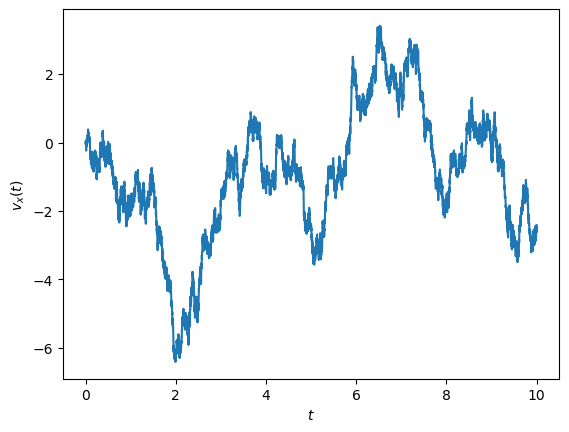

In [10]:
from LSolver import SimulationConfig, underdamped
import numpy as np
import matplotlib.pyplot as plt

gma = 1.0
m = 2.0
D = 10.0
beta = 1/(gma * D)

rng = np.random.default_rng(seed=42)
cfg = SimulationConfig(
    gamma = gma,
    Fx_func = lambda t,x,y: 0.0,
    Tx_func = lambda t,x,y: 1/beta,
    t_max = 10.0,
    dt = 0.001,
    m = m
    )

x, vx, y, vy = underdamped(cfg, rng=rng)

fig, ax = plt.subplots(1,1)
ax.set(xlabel=r"$t$", ylabel=r"$v(t)$")
ax.plot(cfg.t_array, vx)

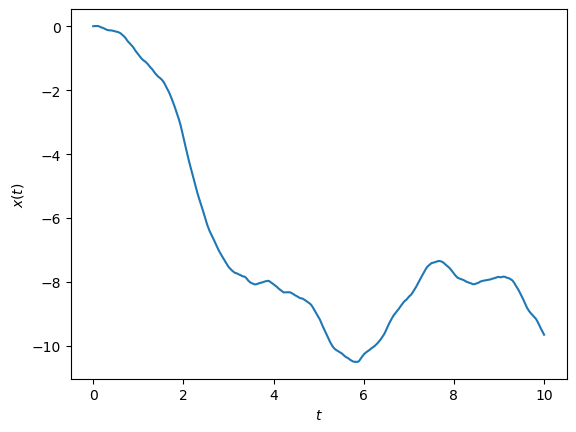

In [11]:
fig, ax = plt.subplots(1,1)
ax.set(xlabel=r"$t$", ylabel=r"$x(t)$")
ax.plot(cfg.t_array, x)

Now we can again explore the dynamics of whole ensemble, mainly its evolution to stationary state. This could help us check whether the simulation results are correct. The distribution with correct normalization factor is
$$P(v) = \sqrt{\frac{\beta m}{2\pi}}\exp{\left(-\frac{\beta mv^2}{2}\right)}.$$

100%|██████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:26<00:00, 37.27it/s]


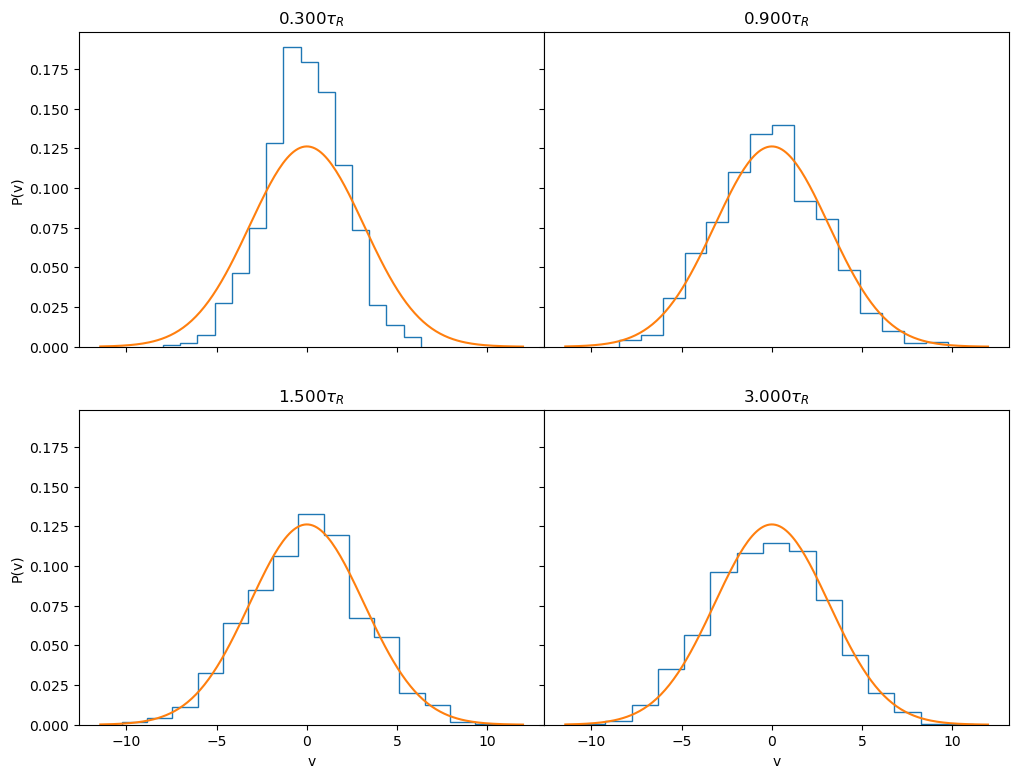

In [45]:
from tqdm import tqdm #optional import for progressbar

rng = np.random.default_rng(seed=2048)

N = 1000
tau = m / gma

cfg = SimulationConfig(
    gamma = gma,
    Fx_func = lambda t,x,y: 0.0,
    Tx_func = lambda t,x,y: 1/beta,
    t_max = 3.0 * tau,
    dt = 0.001,
    m = m
    )

data = np.empty(shape=(N,len(cfg.t_array)))

for k in tqdm(range(N)):
    data[k] = underdamped(cfg, rng=rng)[1]

v = np.linspace(np.min(data), np.max(data), 200)
P = np.sqrt(m * beta / 2 / np.pi) * np.exp(- beta * m * v ** 2 / 2)

fig, axs = plt.subplots(2,2, figsize=(12,9), sharex=True, sharey=True)
fig.subplots_adjust(wspace=0)
axs[0,0].set_ylabel(r"P(v)"), axs[1,0].set(xlabel=r"v", ylabel=r"P(v)"), axs[1,1].set_xlabel(r"v")

for n,m in enumerate([0.1,0.3,0.5,1.0]):
    num = int(m * len(cfg.t_array)) - 1
    counts, bins = np.histogram(data[:,num], density=True, bins=15)
    if n <= 1:
        axs[0,n].stairs(counts, bins)
        axs[0,n].set_title(label=r"{kk:.3f}$\tau_R$".format(kk=m*cfg.t_max/tau))
        axs[0,n].plot(v,P)
    else:
        axs[1,n-2].stairs(counts, bins)
        axs[1,n-2].set_title(label=r"{kk:.3f}$\tau_R$".format(kk=m*cfg.t_max/tau))
        axs[1,n-2].plot(v,P)

Now we will explore the evolution of mean values:

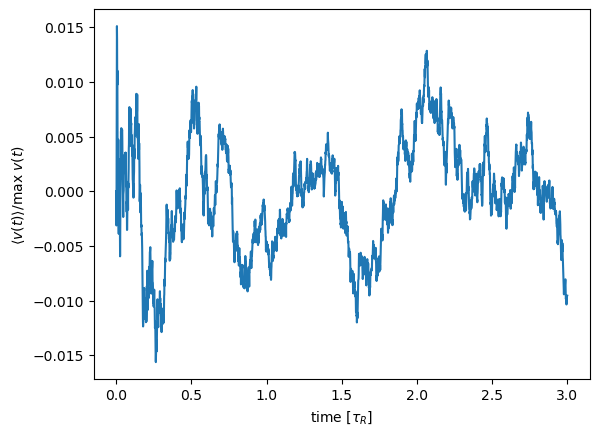

In [46]:
avg = np.empty_like(data[0,:])

avg[0] = 0
avg[1:] = np.mean(data[:, 1:], axis=0) / np.max(data[:, 1:], axis=0)

t = cfg.t_array #np.array([a*cfg.t_max/(len(avg)-1) for a in range(len(avg))])

fig, ax = plt.subplots(1,1)
ax.set(xlabel=r"time [$\tau_R$]", ylabel=r"$\langle v(t)\rangle$/max $v(t)$")
ax.plot(t, avg)

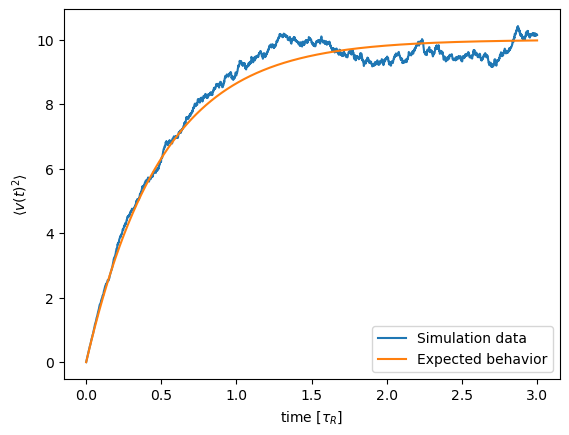

In [47]:
var = np.empty_like(avg)

var = np.mean(data**2, axis=0)

fig, ax = plt.subplots(1,1)
ax.set(xlabel=r"time [$\tau_R$]", ylabel=r"$\langle v(t)^2 \rangle$")
ax.plot(t, var, label="Simulation data")

curve = (1-np.exp(-2*gma*t/m))/(beta * m)
ax.plot(t, curve, label="Expected behavior")
ax.legend(loc="best")

As we can see, everything seems to align with analytical solution of the problem. So far it seems that the implementation of this algorithm works well.

## Constant external force

Next simple example is constant external force, in particular the equation
$$ m\ddot x_t = - \gamma \dot x_t + F_0 + \sqrt{2\gamma k_B T} \xi_t.$$
We can derive the solution in similar manner as in previous example (using integration factor method):
$$\langle v(t) \rangle = \frac{F_0}{\gamma}\left(1 - e^{-\gamma t / m}\right), \qquad \langle (\Delta v(t))^2 \rangle = \frac{k_B T}{m} \left(1 - e^{- 2 \gamma t / m}\right).$$
The mean value of displacement is now more interesting
$$\langle x(t) \rangle = \frac{mF_0}{\gamma^2}\left(e^{-\gamma t / m} - 1\right) + \frac{F_0t}{\gamma}.$$

In [37]:
from tqdm import tqdm #optional import for progressbar

rng = np.random.default_rng(seed=2048)

N = 1000
tau = m / gma
F0 = 3.0

cfg = SimulationConfig(
    gamma = gma,
    Fx_func = lambda t,x,y: F0,
    Tx_func = lambda t,x,y: 1/beta,
    t_max = 5.0 * tau,
    dt = 0.001,
    m = m
    )

x = np.empty(shape=(N,len(cfg.t_array)))
vx = np.empty_like(x)

for k in tqdm(range(N)):
    x[k] = underdamped(cfg, rng=rng)[0]
    vx[k] = underdamped(cfg, rng=rng)[1]

print("Calculation complete")

100%|██████████████████████████████████████████████████████████████████████████████| 1000/1000 [01:27<00:00, 11.49it/s]

Calculation complete


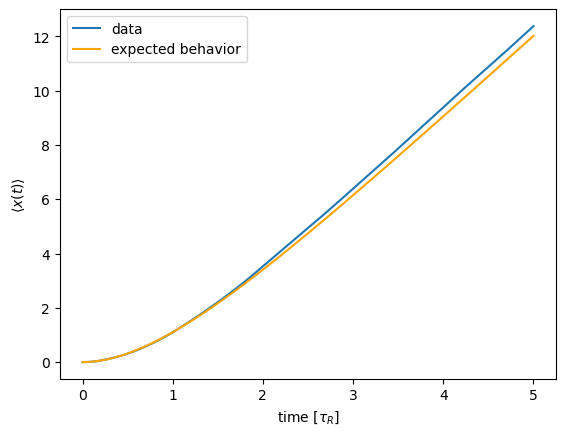

In [42]:
avg = np.empty_like(x[0,:])

avg[0] = 0
avg[1:] = np.mean(x[:, 1:], axis=0)

t = cfg.t_array #np.array([a*cfg.t_max/(len(avg)-1) for a in range(len(avg))])

xm = (m*F0/gma) * (np.exp(-gma*t/m) - 1) + F0*t/gma

fig, ax = plt.subplots(1,1)
ax.set(xlabel=r"time [$\tau_R$]", ylabel=r"$\langle x(t)\rangle$")
ax.plot(t, avg, label="data")
ax.plot(t, xm, color="orange", label="expected behavior")
ax.legend(loc="best")

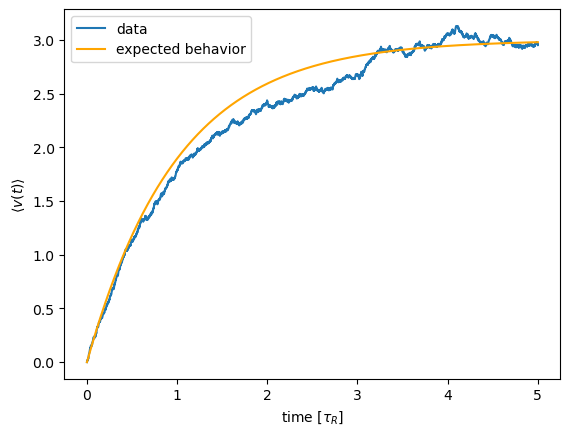

In [41]:
avg = np.empty_like(vx[0,:])

avg[0] = 0
avg[1:] = np.mean(vx[:, 1:], axis=0)

t = cfg.t_array #np.array([a*cfg.t_max/(len(avg)-1) for a in range(len(avg))])
vxm = (F0/gma) * (1 - np.exp(-gma*t/m))

fig, ax = plt.subplots(1,1)
ax.set(xlabel=r"time [$\tau_R$]", ylabel=r"$\langle v(t)\rangle$")
ax.plot(t, avg, label="data")
ax.plot(t, vxm, color="orange", label="expected behavior")
ax.legend(loc="best")

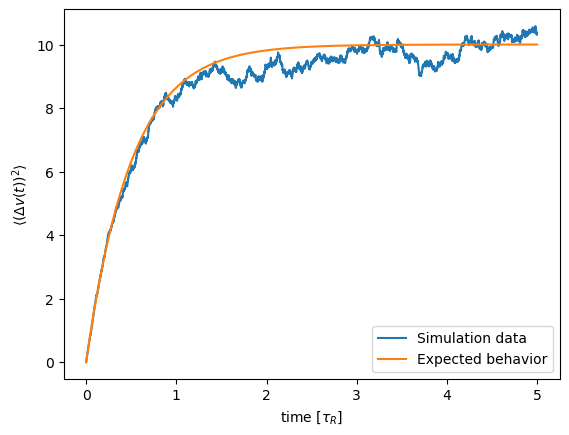

In [43]:
var = np.empty_like(avg)

var = np.mean(vx**2, axis=0) - np.mean(vx,axis=0)**2

fig, ax = plt.subplots(1,1)
ax.set(xlabel=r"time [$\tau_R$]", ylabel=r"$\langle (\Delta v(t))^2 \rangle$")
ax.plot(t, var, label="Simulation data")

curve = (1-np.exp(-2*gma*t/m))/(beta * m)
ax.plot(t, curve, label="Expected behavior")
ax.legend(loc="best")

## Harmonic potential in stationary limit

In the case of harmonic force/potential, we the analytical solution of the equation
$$m\ddot x_t = - \gamma \dot x_t - kx_t + \sqrt{2\gamma k_B T} \xi_t$$
is somewhat complicated, so we will only check the stationary limit results. Since the Boltzmann distribution yields
$$P(x,v) = \frac{1}{Z}\exp\left(-\frac{\beta}{2}(kx^2 + mv^2)\right),$$
the equipartition theorem (or alternatively we can just calculate directly from the distribution) prescribes
$$\langle x \rangle \to \frac{k_B T}{k}, \qquad \langle v \rangle \to \frac{k_B T}{m}.$$

In [59]:
from tqdm import tqdm #optional import for progressbar

rng = np.random.default_rng(seed=2048)

tau = 2 * m / gma
N = 1000
k = 2.0

cfg = SimulationConfig(
    gamma = gma,
    Fx_func = lambda t,x,y: - k * x,
    Tx_func = lambda t,x,y: 1/beta,
    t_max = 5.0 * tau,
    dt = 0.001,
    m = m
    )

x = np.empty(shape=(N,len(cfg.t_array)))
vx = np.empty_like(x)

for r in tqdm(range(N)):
    x[r] = underdamped(cfg, rng=rng)[0]
    vx[r] = underdamped(cfg, rng=rng)[1]

print("Calculation complete")

100%|██████████████████████████████████████████████████████████████████████████████| 1000/1000 [03:05<00:00,  5.40it/s]

Calculation complete


0.1 2.0 5.0


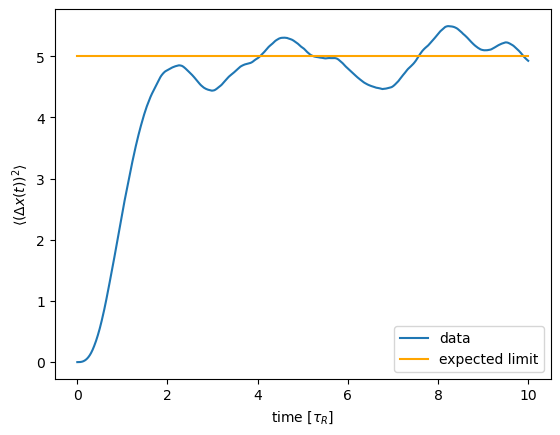

In [60]:
avg = np.empty_like(x[0,:])

var = np.mean(x**2, axis=0) - np.mean(x, axis=0)**2

t = cfg.t_array #np.array([a*cfg.t_max/(len(avg)-1) for a in range(len(avg))])

xm = 1/(beta * k)
print(beta, k, xm)

fig, ax = plt.subplots(1,1)
ax.set(xlabel=r"time [$\tau_R$]", ylabel=r"$\langle (\Delta x(t))^2\rangle$")
ax.plot(t, var, label="data")
ax.plot([0,max(t)], [xm,xm], color="orange", label="expected limit")
ax.legend(loc="best")

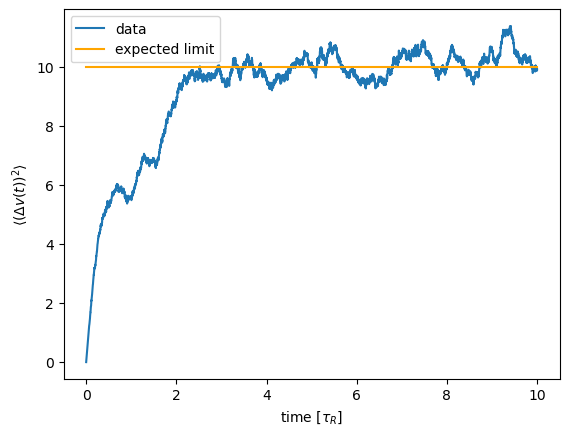

In [61]:
avg = np.empty_like(vx[0,:])

var = np.mean(vx**2, axis=0)- np.mean(vx, axis=0)**2

t = cfg.t_array #np.array([a*cfg.t_max/(len(avg)-1) for a in range(len(avg))])

vxm = 1 / (beta * m)

fig, ax = plt.subplots(1,1)
ax.set(xlabel=r"time [$\tau_R$]", ylabel=r"$\langle (\Delta v(t))^2\rangle$")
ax.plot(t, var, label="data")
ax.plot([0,max(t)], [vxm,vxm], color="orange", label="expected limit")
ax.legend(loc="best")

All of the results listed above seem very promising and we believe that the implemantation of the algorithm of [1] is correct. Furthermore, this algorithm has one great advantage: it is of the order d$t^2$, which means improved convergence for larger time steps d$t$ in contrast with usual linear algorithms.

# References:
[1] Grønbech-Jensen, N., & Farago, O. (2013). *A simple and effective Verlet-type algorithm for simulating Langevin dynamics*. Molecular Physics, 111(8), 983–991. [https://doi.org/10.1080/00268976.2012.760055](https://doi.org/10.1080/00268976.2012.760055)